In [18]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from ipywidgets import interact, FloatSlider, IntSlider

%matplotlib inline

import plotly.io as pio

pio.renderers.default = "iframe"
fig.show()

NameError: name 'fig' is not defined

In [19]:
def func(theta):
    return theta**2

def grad_f(theta):
    return 2*theta

In [20]:
def gradient_descent(start, lr, iterations):
    theta = start
    path = [theta]
    for i in range(iterations):
        theta = theta - lr * grad_f(theta)
        path.append(theta)
    return np.array(path)

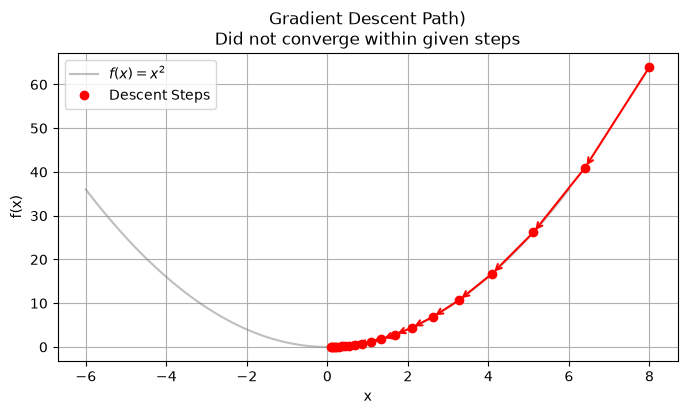

interactive(children=(FloatSlider(value=0.1, description='lr', max=1.0, min=0.01, step=0.01), IntSlider(value=…

<function __main__.plot_gd(lr=0.1, steps=20, start=5.0)>

In [21]:
def plot_gd(lr=0.1, steps=20, start=5.0):
    steps = int(steps)
    path = gradient_descent(start=start, lr=lr, iterations=steps)
    xs = np.linspace(-6, 6, 400)
    ys = func(xs)

    # Compute convergence step
    convergence_eps = 1e-3
    converged_at = next((i for i in range(1, len(path)) if abs(path[i] - path[i-1]) < convergence_eps), None)

    plt.figure(figsize=(8, 4))
    plt.plot(xs, ys, label='$f(x)=x^2$', color='gray', alpha=0.5)

    plt.plot(path, func(path), 'o', color='red', label='Descent Steps')

    for i in range(len(path)-1):
        x0, x1 = path[i], path[i+1]
        y0, y1 = func(x0), func(x1)
        plt.annotate(
            '', xy=(x1, y1), xytext=(x0, y0),
            arrowprops=dict(arrowstyle='->', color='red', lw=1.5)
        )

    title = f'Gradient Descent Path)'
    if converged_at is not None:
        title += f"\nConverged at step {converged_at}"
    else:
        title += "\nDid not converge within given steps"

    plt.title(title)
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.legend()
    plt.grid(True)
    plt.show()




interact(plot_gd, lr=FloatSlider(value=0.1, min=0.01, max=1.0, step=0.01), steps=IntSlider(value=20, min=1, max=100, step=1), start=FloatSlider(value=8.0, min=0.1, max=9.0, step=0.1))

In [22]:

# Define the quadratic loss function and its gradient
def loss(theta):
    """Quadratic loss: (θ1 - 2)^2 + (θ2 - 3)^2"""
    return (theta[0] - 2)**2 + (theta[1] - 3)**2

def grad_loss(theta):
    """Exact gradient of the loss"""
    return np.array([2*(theta[0] - 2), 2*(theta[1] - 3)])


# Batch Gradient Descent
def batch_gd(start, lr, steps):
    """
    Batch gradient descent.

    start: initial point, for example [5, 5]
    lr: learning rate, which controls the step size
    steps: number of gradient descent updates

    At every step, we compute the exact gradient and update

        theta = theta - learning_rate * gradient

    Since the exact gradient is used, the path is usually smooth.
    """
    theta = np.array(start, dtype=float)

    # Store the full trajectory, starting from the initial point.
    path = [theta.copy()]

    for _ in range(steps):
        # Move theta in the direction opposite to the gradient.
        theta -= lr * grad_loss(theta)

        # Save the new position after the update.
        path.append(theta.copy())

    return np.array(path)


# Stochastic Gradient Descent (adds Gaussian noise to gradient)
# Here we mimic SGD by adding Gaussian noise to the exact gradient.
# In real SGD, this noise comes from using one data point or a mini-batch
# instead of the full dataset.
def sgd(start, lr, steps, noise_scale):
    """
    Stochastic gradient descent.

    In real machine learning, we often do not compute the exact full gradient.
    Instead, we estimate it using batches of data.

    This estimate is noisy.

    To mimic that behavior in this simple example, we add random Gaussian noise
    to the exact gradient.
    """
    theta = np.array(start, dtype=float)

    # Store the full trajectory, starting from the initial point.
    path = [theta.copy()]

    for _ in range(steps):
        # Compute the exact gradient first.
        g = grad_loss(theta)

        # Add random noise to imitate a noisy gradient estimate.
        g += np.random.randn(2) * noise_scale

        # Move theta in the direction opposite to the noisy gradient.
        theta -= lr * g

        # Save the new position after the update.
        path.append(theta.copy())

    return np.array(path)

import plotly.graph_objects as go
from ipywidgets import interact, FloatSlider, IntSlider

def plot_descent(lr=0.1, steps=30, noise=0.5, start1=5.0, start2=5.0):
    # Compute trajectories
    bd_path = batch_gd([start1, start2], lr, int(steps))
    sd_path = sgd([start1, start2], lr, int(steps), noise)
    
    # Dynamically choose plotting range around data
    # include both start and optimum (2,3)
    mins = np.min([[start1, start2], [2, 3]], axis=0) - 1
    maxs = np.max([[start1, start2], [2, 3]], axis=0) + 1

    A = np.linspace(mins[0], maxs[0], 100)
    B = np.linspace(mins[1], maxs[1], 100)
    AA, BB = np.meshgrid(A, B)
    ZZ = (AA - 2)**2 + (BB - 3)**2

    # Loss values along the two descent paths
    bd_loss = np.array([loss(p) for p in bd_path])
    sd_loss = np.array([loss(p) for p in sd_path])

    fig = go.Figure()

    # Loss surface
    fig.add_trace(
        go.Surface(
            x=AA,
            y=BB,
            z=ZZ,
            opacity=0.65,
            colorscale="Viridis",
            showscale=False,
            name="Loss surface"
        )
    )

    # Batch gradient descent path
    fig.add_trace(
        go.Scatter3d(
            x=bd_path[:, 0],
            y=bd_path[:, 1],
            z=bd_loss,
            mode="lines+markers",
            name="Batch GD",
            line=dict(width=5),
            marker=dict(size=4)
        )
    )

    # Stochastic gradient descent path
    fig.add_trace(
        go.Scatter3d(
            x=sd_path[:, 0],
            y=sd_path[:, 1],
            z=sd_loss,
            mode="lines+markers",
            name="SGD",
            line=dict(width=5),
            marker=dict(size=4)
        )
    )

    fig.update_layout(
        title=f"GD on f=(θ₁-2)²+(θ₂-3)²<br>lr={lr}, steps={steps}, noise={noise}",
        scene=dict(
            xaxis_title="θ₁",
            yaxis_title="θ₂",
            zaxis_title="Loss"
        ),
        width=900,
        height=700
    )

    fig.show()


interact(
    plot_descent,
    lr=FloatSlider(value=0.1, min=0.001, max=1.0, step=0.001, description='Learning rate'),
    steps=IntSlider(value=30, min=1, max=100, step=1, description='Steps'),
    noise=FloatSlider(value=0.5, min=0.0, max=2.0, step=0.05, description='SGD noise'),
    start1=FloatSlider(value=5.0, min=-5.0, max=10.0, step=0.5, description='θ₁ start'),
    start2=FloatSlider(value=5.0, min=-5.0, max=10.0, step=0.5, description='θ₂ start'),
)

interactive(children=(FloatSlider(value=0.1, description='Learning rate', max=1.0, min=0.001, step=0.001), Int…

<function __main__.plot_descent(lr=0.1, steps=30, noise=0.5, start1=5.0, start2=5.0)>

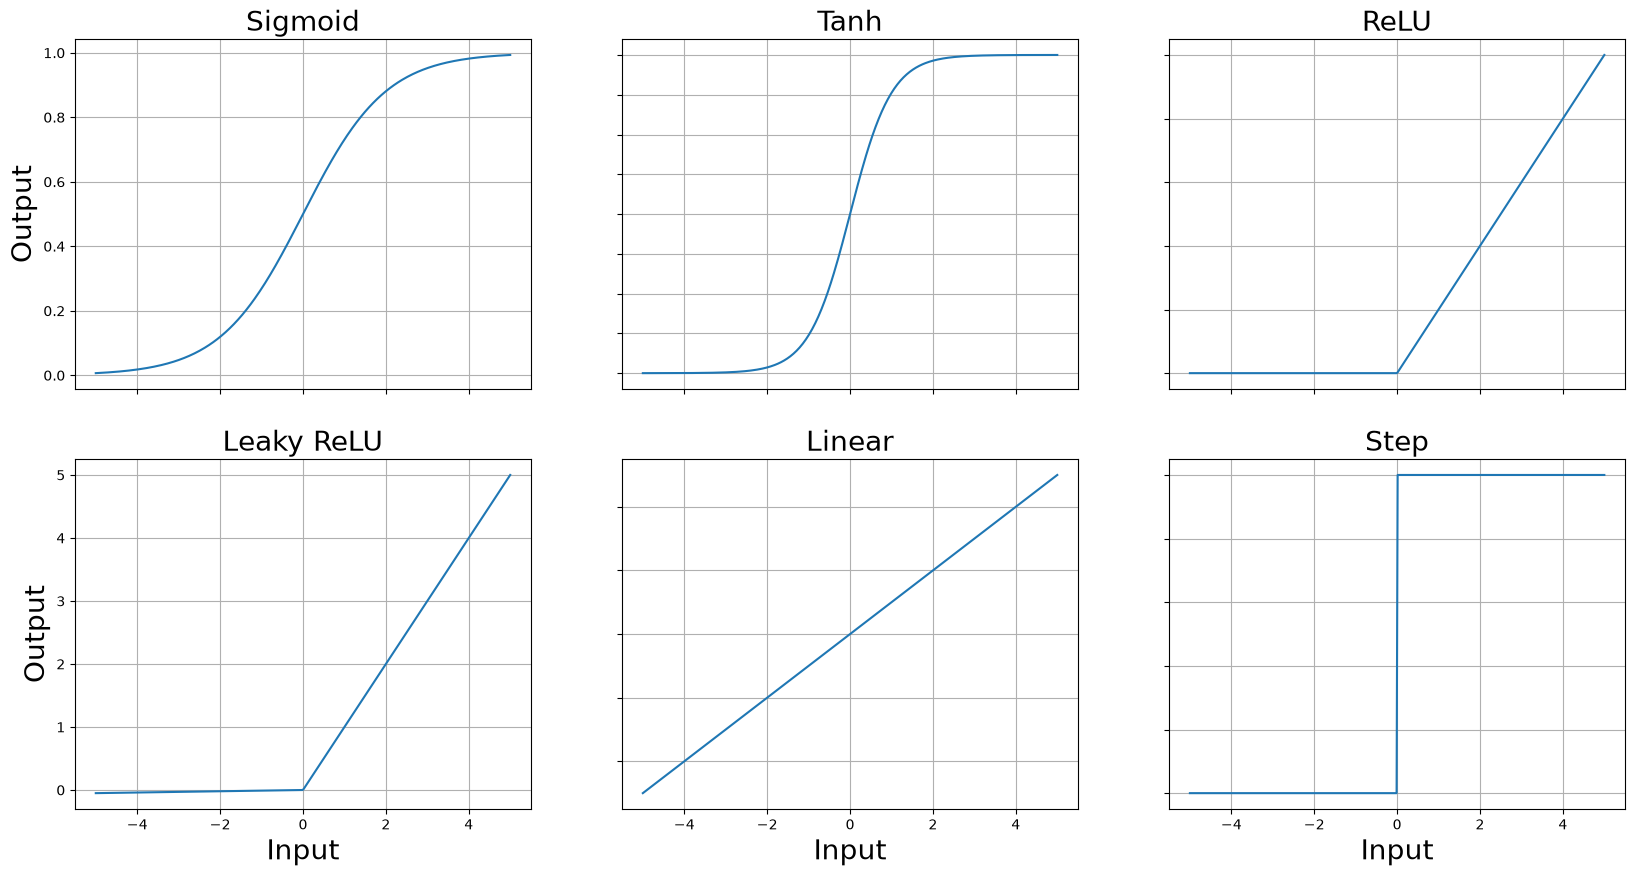

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Define the activation functions
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

def leaky_relu(x, alpha=0.01):
    return np.maximum(alpha * x, x)

def linear(x):
    return x

def step(x):
    return np.where(x >= 0, 1, 0)

# Generate x values
x = np.linspace(-5, 5, 400)

# Calculate y values for each activation function
y_sigmoid = sigmoid(x)
y_tanh = tanh(x)
y_relu = relu(x)
y_leaky_relu = leaky_relu(x)
y_linear = linear(x)
y_step = step(x)

# Plotting
fig, axs = plt.subplots(2, 3, figsize=(20, 10))

plt.rc('axes', titlesize=20)

axs[0,0].plot(x, y_sigmoid, label='Sigmoid')
axs[0,0].set_title('Sigmoid')
axs[0,1].plot(x, y_tanh, label='Tanh')
axs[0,1].set_title('Tanh')
axs[0,2].plot(x, y_relu, label='ReLU')
axs[0,2].set_title('ReLU')
axs[1,0].plot(x, y_leaky_relu, label='Leaky ReLU')
axs[1,0].set_title('Leaky ReLU')
axs[1,1].plot(x, y_linear, label='Linear')
axs[1,1].set_title('Linear')
axs[1,2].plot(x, y_step, label='Step')
axs[1,2].set_title('Step')


for ax in axs.flat:
    x_label = ax.set_xlabel('Input')
    y_label = ax.set_ylabel('Output')
    x_label.set_size(20) 
    y_label.set_size(20)  
    ax.grid(True)

# Hide x labels and tick labels for top plots and y ticks for right plots.
for ax in axs.flat:
    ax.label_outer()


In [2]:
import numpy as np
import matplotlib.pyplot as plt # for plotting
import matplotlib
matplotlib.rcParams['figure.dpi']=300

In [3]:
# calculate f(z) and f'(z)

def net_f_df_sigmoid(z):
    """
    Sigmoid activation and its derivative.

    Input:
        z = weighted input to a neuron

    Output:
        val = sigmoid(z)
        derivative = d(sigmoid)/dz

    We return both because the derivative is needed during backpropagation.
    """
    val = 1/(1 + np.exp(-z)) # sigmoid(z)
    return(val,np.exp(-z)*(val**2)) # return both f and f'


def net_f_df_relu(z):
    """
    ReLU activation and its derivative.

    ReLU(z) = z if z > 0, and 0 otherwise.

    Its derivative is 1 for z > 0 and 0 for z < 0.
    At z = 0 it is not differentiable, but in practice we choose one value.
    """
    val=z*(z>0)
    return(val,z>0) # return both f and f'

In [4]:
def forward_step(y,w,b):
    """
    One forward step from one layer to the next.

    y: activations coming from the previous layer
    w: weights connecting previous layer to next layer
    b: bias of the next layer

    The neuron first computes the weighted sum z = y w + b,
    then applies an activation function.
    """
    z=np.dot(y,w)+b # weighted sum
    return(net_f_df_relu(z)) # activation value and derivative

In [5]:
def apply_net(y_in):
    """
    Full forward pass through the network.

    This function sends the input through all layers of the network.
    We also store intermediate activations and derivatives because
    backpropagation needs them later.
    """
    global Weights, Biases, NumLayers # Try not using global by making all of these as a single class
    global y_layer, df_layer # for storing y-values and df/dz values
    
    y = y_in # start with input values
    y_layer[0] = y
    for j in range(NumLayers): # loop through all layers
        # j=0 corresponds to the first layer above the input
        y,df = forward_step(y,Weights[j],Biases[j]) # one layer update
        df_layer[j] = df # store f'(z), needed later in backprop
        y_layer[j+1] = y # store activation value, also needed later
    return(y)

In [6]:
def backward_step(delta,w,df):
    """
    Propagate the error signal one layer backwards.

    delta measures how much the current layer contributed to the loss.
    Multiplying by the transposed weight matrix sends this information
    back to the previous layer. Multiplying by df applies the chain rule.
    """
    return( np.dot(delta,np.transpose(w))*df )


def backprop(y_target):
    """
    One backward pass through the network.

    This computes gradients of the loss with respect to all weights and biases.
    These gradients are stored in dw_layer and db_layer.
    """
    global y_layer, df_layer, Weights, Biases, NumLayers
    global dw_layer, db_layer # dCost/dw and dCost/db 
    global batchsize
    
    # Error at the output layer.
    # For MSE loss, the first factor is predicted - target.
    # The second factor comes from the derivative of the activation function.
    delta = (y_layer[-1]-y_target)*df_layer[-1]

    # Gradients for the last layer.
    dw_layer[-1] = np.dot(np.transpose(y_layer[-2]),delta)/batchsize
    db_layer[-1] = delta.sum(0)/batchsize

    # Move backwards through the remaining layers.
    for j in range(NumLayers-1):
        delta = backward_step(delta,Weights[-1-j],df_layer[-2-j])
        dw_layer[-2-j] = (np.dot(np.transpose(y_layer[-3-j]),delta)/batchsize)
        db_layer[-2-j] = delta.sum(0)/batchsize

In [7]:
def gradient_step(eta):
    """
    Update weights and biases using gradient descent.

    eta is the learning rate.
    Larger eta means bigger steps, but too large values can make training unstable.
    """
    global dw_layer, db_layer, Weights, Biases
    
    for j in range(NumLayers):
        Weights[j]-=eta*dw_layer[j]
        Biases[j]-=eta*db_layer[j]

In [8]:
def train_net(y_in,y_target,eta):
    """
    One complete training step on one batch.

    The order is:
        1. forward pass
        2. backward pass
        3. gradient descent update
        4. return the loss/cost
    """
    global y_out_result
    
    y_out_result = apply_net(y_in)
    backprop(y_target)
    gradient_step(eta)
    cost = ((y_target-y_out_result)**2).sum()/batchsize
    return(cost)

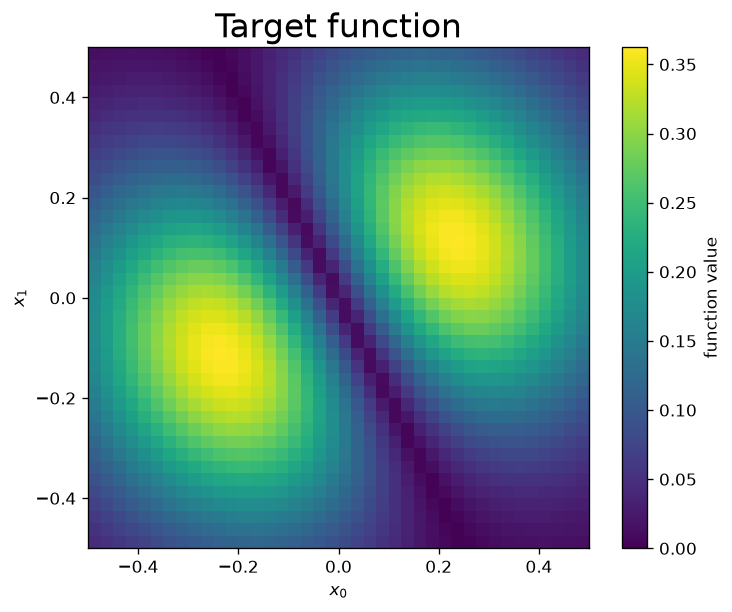

Target-function range: 0.001470635631948683 0.36236320786208664


In [9]:
def myFunc(x0,x1):
    """
    A simple two-variable function for the NumPy network to learn.

    The input is a point (x0, x1) in the plane.
    The output is one number.

    We choose a function with a localized bump-like structure so that
    one can visually see whether the network is learning the shape.
    """
    r2=x0**2+x1**2
    return(np.exp(-7*r2)*np.abs(x1+2*x0))

xrange = np.linspace(-0.5, 0.5, 40)
X0, X1 = np.meshgrid(xrange, xrange)

target_grid = myFunc(X0, X1)

image_extent = [
    xrange.min(),
    xrange.max(),
    xrange.min(),
    xrange.max(),
]

# Use the target-function range for every image.
image_vmin = 0.0
image_vmax = target_grid.max()

fig, ax = plt.subplots(figsize=(6.5, 5.2), dpi=120)

image = ax.imshow(
    target_grid,
    interpolation="nearest",
    origin="lower",
    extent=image_extent,
    aspect="equal",
    vmin=image_vmin,
    vmax=image_vmax,
)

ax.set_xlabel(r"$x_0$")
ax.set_ylabel(r"$x_1$")
ax.set_title("Target function")

fig.colorbar(image, ax=ax, label="function value")
plt.tight_layout()
plt.show()

print(
    "Target-function range:",
    target_grid.min(),
    target_grid.max(),
)

In [10]:
def make_batch():
    """
    Create one random training batch.

    Each training example is a random point (x0, x1) in the square [-0.5, 0.5].
    The target is the value of myFunc(x0, x1).

    This is the NumPy version of what a DataLoader usually does for us in PyTorch.
    """
    global batchsize

    inputs = np.random.uniform(low=-0.5,high=+0.5,size=[batchsize,2])
    targets = np.zeros([batchsize,1]) # must have right dimensions
    targets[:,0] = myFunc(inputs[:,0],inputs[:,1])
    return(inputs,targets)

In [11]:
# Let us first create the network.

# NumLayers counts the layers that have trainable weights.
# It does not count the input layer, but it does count the output layer.
NumLayers = 2

# LayerSizes tells us the size of each layer.
# Here: 2 input features -> 100 hidden neurons -> 1 output value.
LayerSizes = [2, 100, 1]

# Initialize random weights and zero biases for all layers.
# Small random weights help break symmetry between neurons.
Weights = [np.random.uniform(low=-0.1,high=+0.1,size=[ LayerSizes[j],LayerSizes[j+1] ]) for j in range(NumLayers)]
Biases = [np.zeros(LayerSizes[j+1]) for j in range(NumLayers)]

# Batch size = number of examples used in one training update.
batchsize=100

# Helper arrays for the forward and backward passes.
# y_layer stores activations, df_layer stores activation derivatives,
# and dw_layer/db_layer store gradients.
y_layer = [np.zeros([batchsize,LayerSizes[j]]) for j in range(NumLayers+1)]
df_layer = [np.zeros([batchsize,LayerSizes[j+1]]) for j in range(NumLayers)]
dw_layer = [np.zeros([LayerSizes[j],LayerSizes[j+1]]) for j in range(NumLayers)]
db_layer = [np.zeros(LayerSizes[j+1]) for j in range(NumLayers)]

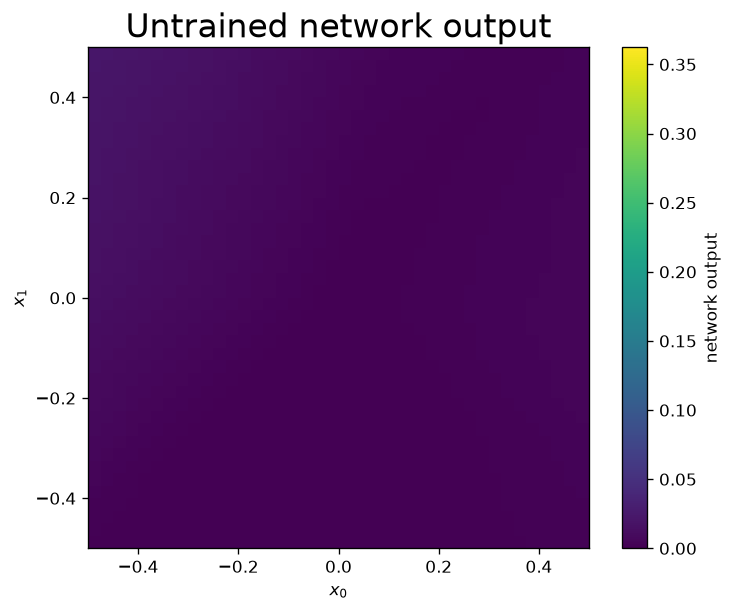

Network-output range: -0.0 0.022117695283321588


In [12]:
# First we try without training the network.
# Since the weights are random, the output should not look like the target function yet.

def apply_net_simple(y_in):
    """Forward pass used only for plotting/testing, without storing backprop information."""
    y = y_in
    y_layer[0] = y
    for j in range(NumLayers):
        y,df = forward_step(y,Weights[j],Biases[j])
    return(y)

# Combine the grid coordinates into inputs of shape (number of points, 2).
testsample = np.column_stack([
    X0.ravel(),
    X1.ravel(),
])

# Evaluate the untrained network.
testoutput = apply_net_simple(testsample)
testoutput_grid = np.asarray(testoutput).reshape(X0.shape)

fig, ax = plt.subplots(figsize=(6.5, 5.2), dpi=120)

image = ax.imshow(
    testoutput_grid,
    interpolation="nearest",
    origin="lower",
    extent=image_extent,
    aspect="equal",
    vmin=image_vmin,
    vmax=image_vmax,
)

ax.set_xlabel(r"$x_0$")
ax.set_ylabel(r"$x_1$")
ax.set_title("Untrained network output")

fig.colorbar(image, ax=ax, label="network output")
plt.tight_layout()
plt.show()

print(
    "Network-output range:",
    testoutput_grid.min(),
    testoutput_grid.max(),
)

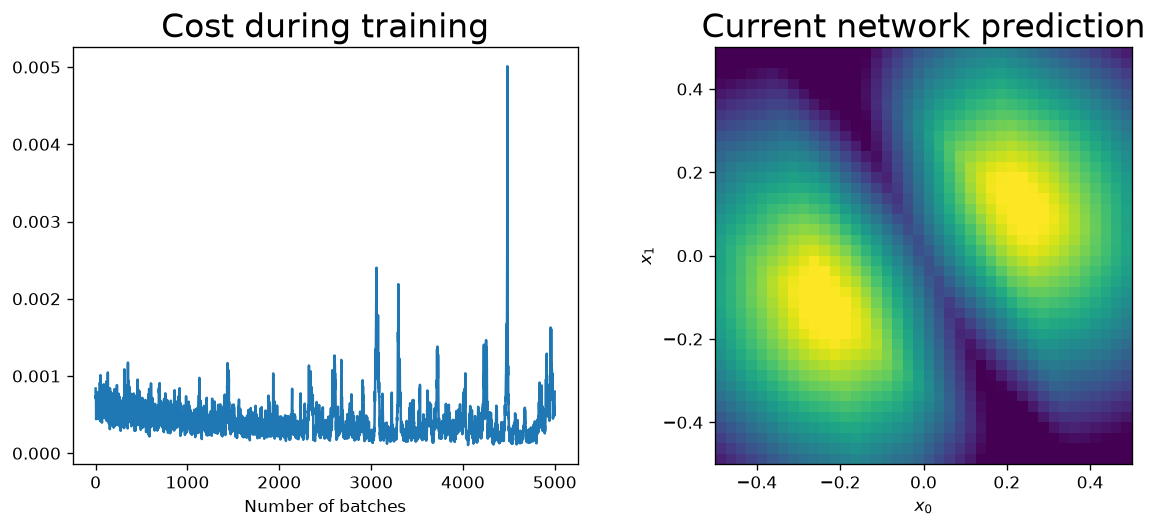

In [14]:
# Import functions for updating display.
# This creates a simple animation during training.
from IPython.display import clear_output
from time import sleep

eta = 1 # learning rate
nsteps = 5000
plot_every = 40

costs = np.zeros(nsteps)
for j in range(nsteps):
    
    # Create a fresh random batch.
    y_in,y_target = make_batch()

    # Train the network on this batch.
    costs[j] = train_net(y_in,y_target,eta)

    # Update the display only occasionally.
    if j % plot_every == 0 or j == nsteps - 1:

        clear_output(wait = True)
        # Evaluate the updated network on the full grid for visualization.
        testoutput = apply_net_simple(testsample)
    
        fig, ax = plt.subplots(
        ncols=2,
        nrows=1,
        figsize=(10, 4.5),
        dpi=120,
        ) # prepare figure

        ax[0].plot(costs)

        img = ax[1].imshow(
            np.asarray(testoutput).reshape(X0.shape),
            interpolation="nearest",
            origin="lower",
            extent=image_extent,
            aspect="equal",
            vmin=image_vmin,
            vmax=image_vmax,
        )

        ax[0].set_title("Cost during training")
        ax[0].set_xlabel("Number of batches")

        ax[1].set_title("Current network prediction")
        ax[1].set_xlabel(r"$x_0$")
        ax[1].set_ylabel(r"$x_1$")

        plt.tight_layout()
        plt.show()
        sleep(0.1)

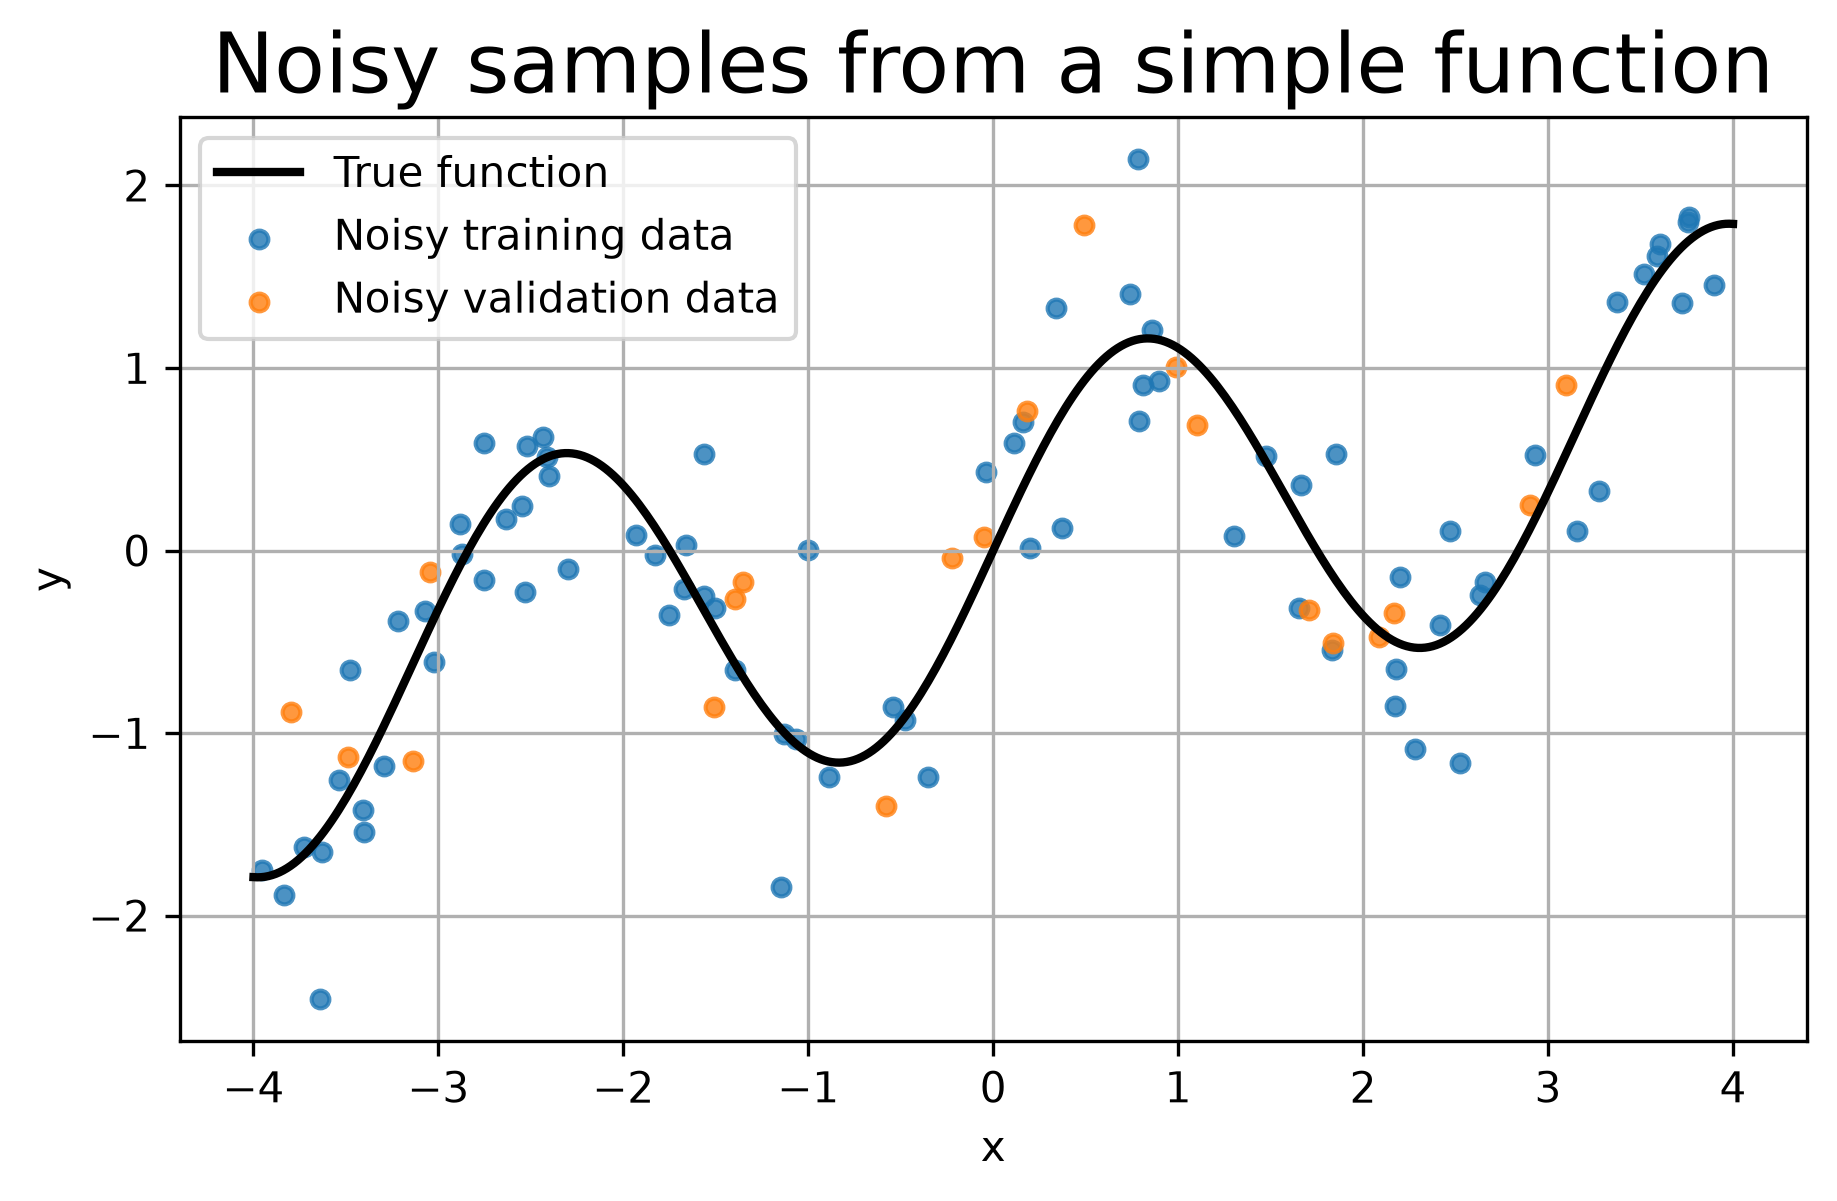

In [16]:
import numpy as np

import torch
# from torchinfo import summary
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Fix the random seeds for reproducibility.
np.random.seed(42)
torch.manual_seed(42)


def true_function(x):
    """
    The hidden function that generates the clean signal.

    The network will not directly see this function.
    It will only see noisy samples from it.
    """
    return np.sin(2*x) + 0.2*x


# Number of points used for training and validation.
N_train = 80
N_val = 20

# Random x-values for training and validation.
# Sorting is only done to make plots easier to read.
X_train_np = np.sort(np.random.uniform(-4, 4, size=(N_train, 1)), axis=0)
X_val_np   = np.sort(np.random.uniform(-4, 4, size=(N_val, 1)), axis=0)

# Noise level in the observed data.
noise_level = 0.45

# Clean target values.
Y_train_clean = true_function(X_train_np)
Y_val_clean   = true_function(X_val_np)

# Noisy observed values.
# This imitates the fact that real data rarely sit perfectly on the true curve.
Y_train_np = Y_train_clean + noise_level*np.random.randn(N_train, 1)
Y_val_np   = Y_val_clean   + noise_level*np.random.randn(N_val, 1)

# A dense grid used only for drawing the true curve and the model prediction.
X_plot_np = np.linspace(-4, 4, 400).reshape(-1, 1)
Y_plot_np = true_function(X_plot_np)

# Plot the data and the hidden true function.
plt.figure(figsize=(7,4))
plt.plot(X_plot_np, Y_plot_np, 'k-', linewidth=2, label='True function')
plt.scatter(X_train_np, Y_train_np, s=18, alpha=0.8, label='Noisy training data')
plt.scatter(X_val_np, Y_val_np, s=18, alpha=0.8, label='Noisy validation data')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Noisy samples from a simple function')
plt.legend()
plt.grid(True)
plt.show()


In [17]:
# Convert NumPy arrays to PyTorch tensors.
# PyTorch models expect tensors, usually in float32 precision.
X_train = torch.from_numpy(X_train_np).float()
Y_train = torch.from_numpy(Y_train_np).float()
X_val   = torch.from_numpy(X_val_np).float()
Y_val   = torch.from_numpy(Y_val_np).float()
X_plot  = torch.from_numpy(X_plot_np).float()

# TensorDataset simply pairs inputs and targets together.
train_set = TensorDataset(X_train, Y_train)
val_set   = TensorDataset(X_val, Y_val)

# DataLoader gives mini-batches during training.
# shuffle=True means each epoch sees the training examples in a new random order.
train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=32, shuffle=False)


In [20]:
class SimpleNet(nn.Module):
    """
    A simple neural network for one-dimensional regression.

    hidden controls the number of neurons in the hidden layer.
    A small hidden value gives a simple model.
    A large hidden value gives a more flexible model.
    """
    def __init__(self, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden),  # input x -> hidden neurons
            nn.ReLU(),             # nonlinearity
            nn.Linear(hidden, 1)   # hidden neurons -> output y
        )

    def forward(self, x):
        return self.net(x)


model = SimpleNet(hidden=32)

# Print the architecture of the model.
# This is the standard lightweight PyTorch way to inspect a model.
# print(summary(model))
print("\n\n")
print(model)# just to add some space between the two printouts
#print(model) # This is the more basic way to print the model, but it does not show the number of parameters.





SimpleNet(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [21]:

# Count the number of trainable parameters.
# model.parameters() gives all weights and biases.
# p.numel() counts how many numbers are inside each parameter tensor.
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Trainable parameters:", num_params)


Trainable parameters: 97
